# Local dataset readiness: real EDA and independent split preparation

No model inference or downloads. Protocol and selected IDs are saved before decoding/screening. All similarity decisions are conservative preparation evidence, not proof of semantic uniqueness or scientific benchmark completion. Failed attempts are retained separately.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, subprocess
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
assert (ROOT / "experiments/scripts").is_dir()
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN = ROOT / "experiments/outputs/dataset_readiness_260926" / STAMP
RUN.mkdir(parents=True)
BUNDLE = RUN / "bundle"
os.environ.update(HF_HUB_OFFLINE="1", HF_DATASETS_OFFLINE="1", TRANSFORMERS_OFFLINE="1", PYTHONIOENCODING="utf-8")
commands = []
def command(args, accepted=(0,)):
    try:
        result = subprocess.run(args, cwd=ROOT, text=True, encoding="utf-8", errors="replace", capture_output=True, timeout=1200)
    except subprocess.TimeoutExpired as error:
        def readable(value):
            return value.decode("utf-8", errors="replace") if isinstance(value, bytes) else (value or "")
        entry = dict(command=args, exit_code=None, accepted=False, timeout_seconds=1200,
                     stdout=readable(error.stdout), stderr=readable(error.stderr))
        commands.append(entry)
        (RUN / "commands.json").write_text(json.dumps(commands, indent=2), encoding="utf-8")
        print("TIMEOUT", args, entry["stdout"], entry["stderr"])
        raise
    entry = dict(command=args, exit_code=result.returncode, accepted=result.returncode in accepted, stdout=result.stdout, stderr=result.stderr)
    commands.append(entry)
    (RUN / "commands.json").write_text(json.dumps(commands, indent=2), encoding="utf-8")
    print("COMMAND", args, "EXIT", result.returncode)
    print(result.stdout)
    if result.stderr: print(result.stderr)
    return result
print("Execution output:", RUN)


Execution output: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\dataset_readiness_260926\20260926T101747121197Z


## Regression checks
Fixtures validate protocol decisions and integrity failures. These test counts do not measure model quality.

In [2]:
command([sys.executable, "-m", "compileall", "-q", "experiments/scripts/dataset_readiness_selection.py", "experiments/scripts/dataset_readiness_screening.py", "experiments/scripts/dataset_readiness_figures.py", "experiments/scripts/run_dataset_readiness.py"])
command([sys.executable, "-m", "pytest", "-q", "tests/test_dataset_readiness_selection.py", "tests/test_dataset_readiness_screening.py", "tests/test_dataset_readiness_figures.py"])
command(["git", "diff", "--check"])
assert all(c["accepted"] for c in commands), "Regression checks failed; see outputs"


COMMAND ['C:\\Users\\hung\\AppData\\Local\\Programs\\Python\\Python311\\python.exe', '-m', 'compileall', '-q', 'experiments/scripts/dataset_readiness_selection.py', 'experiments/scripts/dataset_readiness_screening.py', 'experiments/scripts/dataset_readiness_figures.py', 'experiments/scripts/run_dataset_readiness.py'] EXIT 0



COMMAND ['C:\\Users\\hung\\AppData\\Local\\Programs\\Python\\Python311\\python.exe', '-m', 'pytest', '-q', 'tests/test_dataset_readiness_selection.py', 'tests/test_dataset_readiness_screening.py', 'tests/test_dataset_readiness_figures.py'] EXIT 0
.................................                                        [100%]
============================== warnings summary ===============================
tests/test_dataset_readiness_figures.py: 10 warnings
  C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\scripts\dataset_readiness_figures.py:23: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
    cmap.set_bad("#eeeeee")

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
33 passed, 10 warnings in 4.65s

COMMAND ['git', 'diff', '--check'] EXIT 0




## Local selection, extraction, similarity screening and measured EDA
Exit 3 means preparation is blocked; preserve diagnostics without treating it as scientific success.

In [3]:
command([sys.executable, "-m", "experiments.scripts.run_dataset_readiness", "--output", str(BUNDLE)], accepted=(0, 3))
assert commands[-1]["accepted"], "Readiness execution failed; see captured logs"


COMMAND ['C:\\Users\\hung\\AppData\\Local\\Programs\\Python\\Python311\\python.exe', '-m', 'experiments.scripts.run_dataset_readiness', '--output', 'C:\\Users\\hung\\Documents\\GitHub\\multimodal-lecture-summarizer\\multimodal-lecture-summarizer\\experiments\\outputs\\dataset_readiness_260926\\20260926T101747121197Z\\bundle'] EXIT 0
Protocol and selected IDs saved before selected-media decoding
{"dataset_id": "tedlium3", "status": "screened_under_protocol", "comparisons": 2225, "selected_count": 50, "retained_count": 42, "historical_count": 20, "retained_cross_split_hits": 0, "retained_historical_hits": 0, "cohort_counts": {"validation": 30, "final_test": 20, "historical": 20}, "pair_coverage": [{"left_split": "final_test", "right_split": "final_test", "expected_pairs": 190, "completed_pairs": 190}, {"left_split": "final_test", "right_split": "historical", "expected_pairs": 400, "completed_pairs": 400}, {"left_split": "final_test", "right_split": "validation", "expected_pairs": 600, "c

## Receipt verification and tables
All referenced bytes are checked before displaying them.

In [4]:
from experiments.scripts.benchmark_artifacts import sha256_file
receipt = json.loads((BUNDLE / "bundle-receipt.json").read_text(encoding="utf-8"))
for item in receipt["files"]:
    path = (BUNDLE / item["path"]).resolve()
    path.relative_to(BUNDLE.resolve())
    assert sha256_file(path) == item["sha256"], item["path"]
print("Verified bundle files:", len(receipt["files"]))
summary = json.loads((BUNDLE / "summary.json").read_text(encoding="utf-8"))
display(pd.DataFrame(summary).T)
selection = json.loads((BUNDLE / "selection.json").read_text(encoding="utf-8"))
display(Markdown("Protocol fixed before extraction:"))
display(pd.json_normalize(json.loads((BUNDLE / "protocol.json").read_text(encoding="utf-8"))))
for dataset in summary:
    rows = json.loads((BUNDLE / dataset / "units.json").read_text(encoding="utf-8"))
    audit = json.loads((BUNDLE / dataset / "screening.json").read_text(encoding="utf-8"))
    display(Markdown(f"### {dataset}: {audit['status']}"))
    display(pd.DataFrame(rows).groupby(["split", "decision"]).size().rename("units").reset_index())
    display(pd.DataFrame(rows).head(10))
    display(Markdown(f"Similarity hits: {len(audit['pairs'])}; showing first 20. Full pair decisions are saved in screening.json."))
    display(pd.DataFrame(audit["pairs"][:20]))
    print("Blockers:", audit["blockers"])


Verified bundle files: 122


,dataset_id,status,comparisons,selected_count,retained_count,historical_count,retained_cross_split_hits,retained_historical_hits,cohort_counts,pair_coverage,blockers,limitations,pair_count,failure_count,figures
tedlium3,tedlium3,screened_under_protocol,2225,50,42,20,0,0,"{'validation': 30, 'final_test': 20, 'historic...","[{'left_split': 'final_test', 'right_split': '...",[],"[dHash is not semantic image matching, wavefor...",0,8,8
iiit_cvid,iiit_cvid,screened_under_protocol,2653056,2304,2301,0,0,0,"{'validation': 549, 'final_test': 1755}","[{'left_split': 'final_test', 'right_split': '...",[],"[dHash is not semantic image matching, wavefor...",6455,0,8


Protocol fixed before extraction:

,version,selection_salt,ted_validation_units,ted_test_units,minimum_groups_per_split,image_dhash_size,image_dhash_max_distance,audio_fingerprint_samples,audio_correlation_min,audio_relative_duration_tolerance,...,conflict_policy,failure_policy,histogram_bytes_edges,histogram_duration_edges,scope,limitations,minimum_retained.tedlium3.validation,minimum_retained.tedlium3.final_test,minimum_retained.iiit_cvid.validation,minimum_retained.iiit_cvid.final_test
0,dataset-readiness-v1,dataset-readiness-v1,30,20,2,8,6,4096,0.995,0.01,...,exclude_validation_for_cross_split; exclude_ne...,exclude_no_replacement; block_if_insufficient_...,"[0, 10000, 50000, 100000, 250000, 500000, 1000...","[0, 1, 2, 5, 10, 20, 30, 60, 120, 600]",preparation evidence screened under protocol; ...,"[dHash is not semantic image matching, wavefor...",20,15,30,30


### tedlium3: screened_under_protocol

,split,decision,units
0,final_test,exclude,4
1,final_test,keep,16
2,validation,exclude,4
3,validation,keep,26


... (6 outputs left out)

,dataset_id,unit_id,split,original_split,speaker_id,talk_id,source_id,input_media_path,annotation_path,decoded,...,decode_error,ground_truth_error,image_width_px,image_height_px,image_mode,annotation_sha256,annotation_source,text_line_count,decision,reasons
0,iiit_cvid,validation:11:1:00_19_55_00001,validation,val,course_11,11_1,11/1,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,c48db8cf019ff42d9b8753cf1a62d0b902d9e308217c8d...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,57,keep,[]
1,iiit_cvid,validation:11:1:00_28_05_00002,validation,val,course_11,11_1,11/1,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,7c2416fd7393b4067f4f009683b331ef01fb1343606700...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,30,keep,[]
2,iiit_cvid,validation:11:1:00_33_35_00003,validation,val,course_11,11_1,11/1,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,d1339ddb7d4cfe9eb9c700b4fc4e4dab173af311bfc28c...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,19,keep,[]
3,iiit_cvid,validation:11:10:00_04_36_00001,validation,val,course_11,11_10,11/10,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,6a0f06742a5f05e74ba78773e0bfce72ba6960b51281b3...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,24,keep,[]
4,iiit_cvid,validation:11:10:00_40_34_00002,validation,val,course_11,11_10,11/10,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,4d5e557bc4e0da28429581c2c1fd7943483784e514af80...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,15,keep,[]
5,iiit_cvid,validation:11:11:00_02_09_00001,validation,val,course_11,11_11,11/11,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,7e021350eb5ca4f959d3bb567c5eb7c42cd78e293e6dea...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,18,keep,[]
6,iiit_cvid,validation:11:11:00_27_19_00002,validation,val,course_11,11_11,11/11,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,dbffbaaf9844bdff0219974c928a7b8511bc7148ad871c...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,22,keep,[]
7,iiit_cvid,validation:11:12:00_05_38_00001,validation,val,course_11,11_12,11/12,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,e6b3c0c1e7e5163a48a8f2872c546ce402aeb1dda21b11...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,25,keep,[]
8,iiit_cvid,validation:11:12:00_40_18_00002,validation,val,course_11,11_12,11/12,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,bc6b9571dc5a4a9b1caac7ae360840242a2e8dd93bde47...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,8,keep,[]
9,iiit_cvid,validation:11:12:00_46_48_00003,validation,val,course_11,11_12,11/12,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,True,...,None,None,608,482,RGB,50c01b4f864c51fa2ba8e76c1c97131c01f206d034de3c...,experiments/datasets/iiit_cvid/IIIT-CVid/Frame...,24,keep,[]


Similarity hits: 6455; showing first 20. Full pair decisions are saved in screening.json.

,kind,method,score,threshold,left,right,left_split,right_split,decision,excluded_unit_id,reason
0,near,dhash_hamming,6,6,validation:11:18:00_11_32_00002,final_test:10:1:00_13_09_00002,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
1,near,dhash_hamming,6,6,validation:11:18:00_11_32_00002,final_test:10:12:00_37_45_00006,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
2,near,dhash_hamming,4,6,validation:11:18:00_11_32_00002,final_test:10:14:00_08_14_00003,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
3,near,dhash_hamming,4,6,validation:11:18:00_11_32_00002,final_test:10:14:00_17_32_00005,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
4,near,dhash_hamming,5,6,validation:11:18:00_11_32_00002,final_test:10:15:00_16_25_00003,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
5,near,dhash_hamming,6,6,validation:11:18:00_11_32_00002,final_test:10:15:00_50_18_00010,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
6,near,dhash_hamming,5,6,validation:11:18:00_11_32_00002,final_test:10:17:00_15_55_00004,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
7,near,dhash_hamming,6,6,validation:11:18:00_11_32_00002,final_test:10:17:00_27_43_00005,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
8,near,dhash_hamming,6,6,validation:11:18:00_11_32_00002,final_test:10:17:00_53_26_00009,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule
9,near,dhash_hamming,4,6,validation:11:18:00_11_32_00002,final_test:10:18:00_05_21_00001,validation,final_test,exclude,validation:11:18:00_11_32_00002,predeclared conservative conflict rule


Blockers: []


## Actual universal plots
Eight per dataset. Still-image duration is explicitly not applicable; it is never represented as zero duration.

**tedlium3 — scale_bytes**

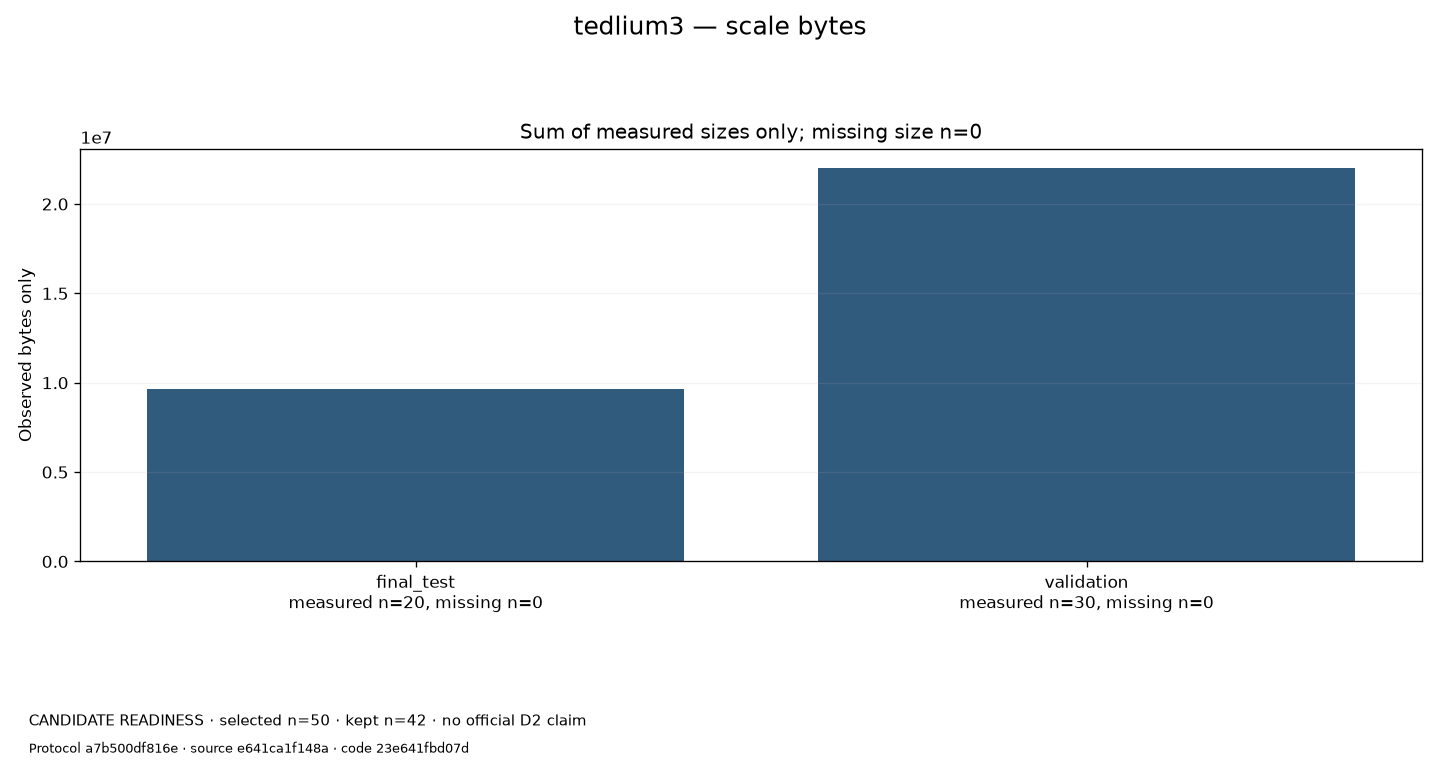

**tedlium3 — duration_distribution**

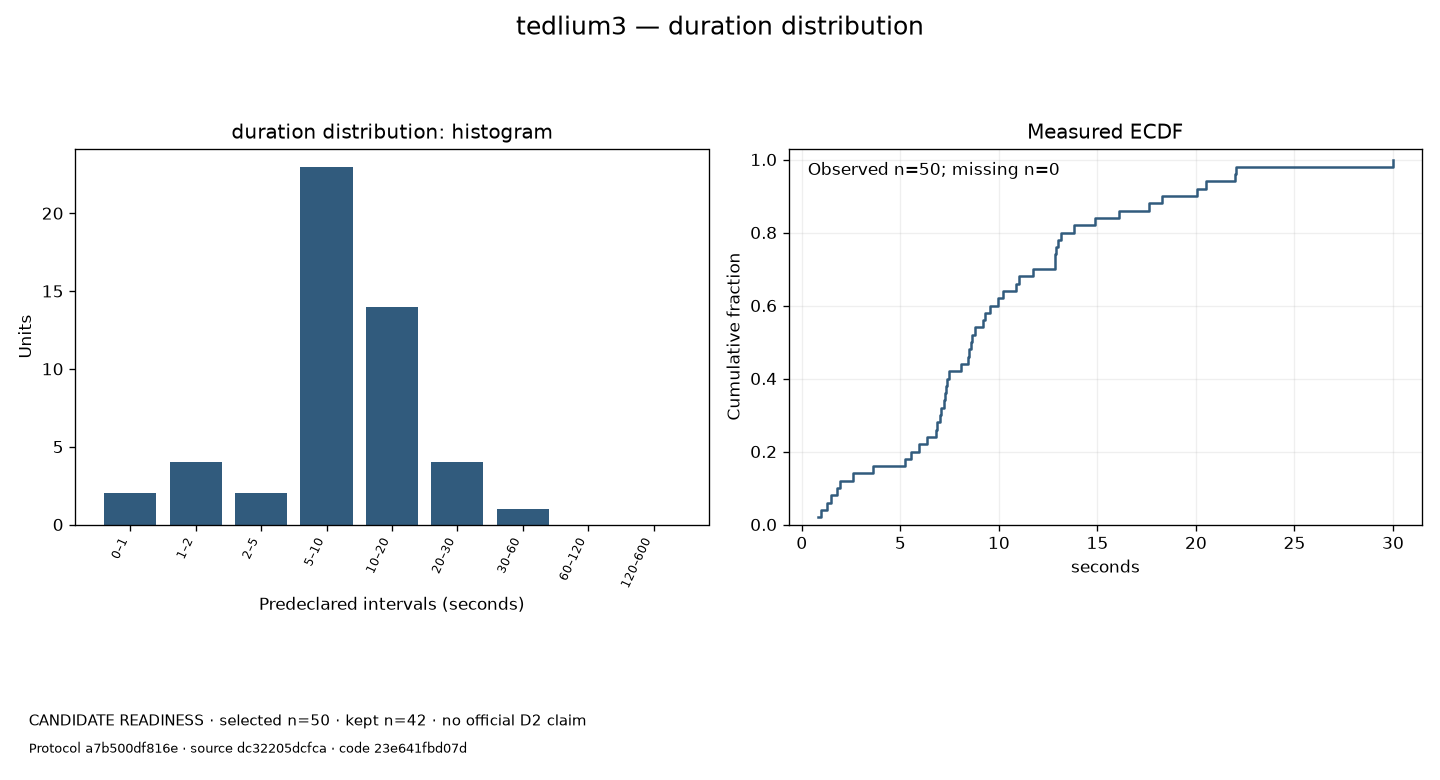

**tedlium3 — file_size_distribution**

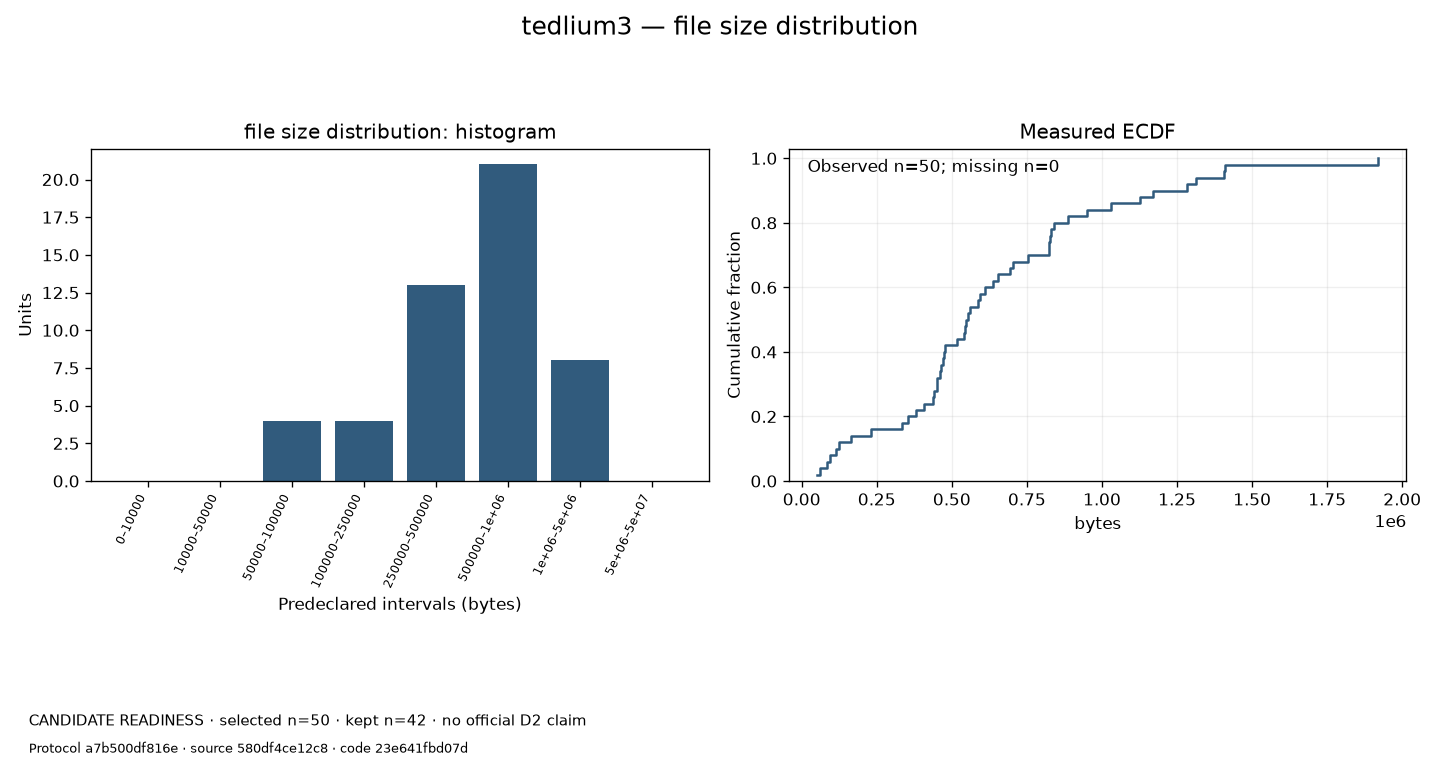

**tedlium3 — missingness_gt_coverage**

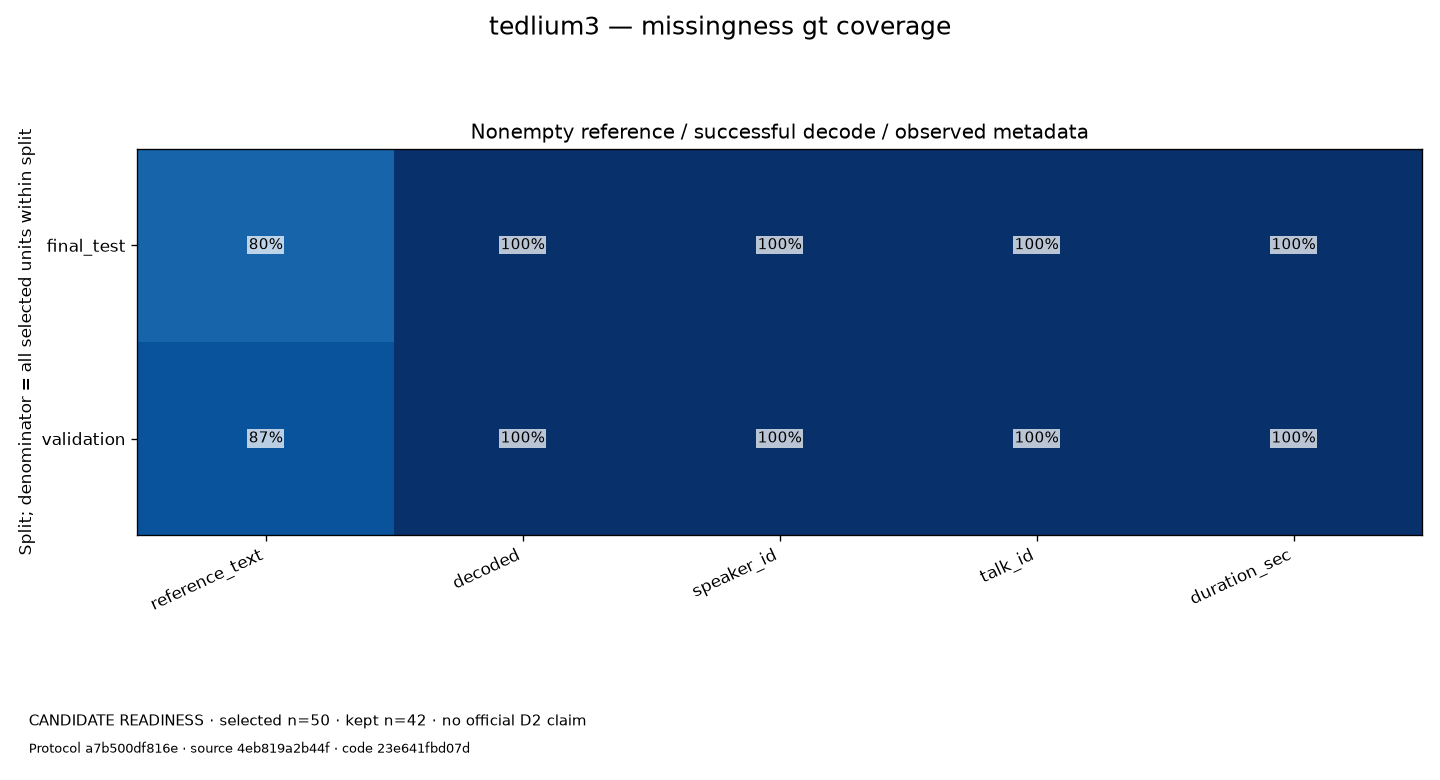

**tedlium3 — attrition_waterfall**

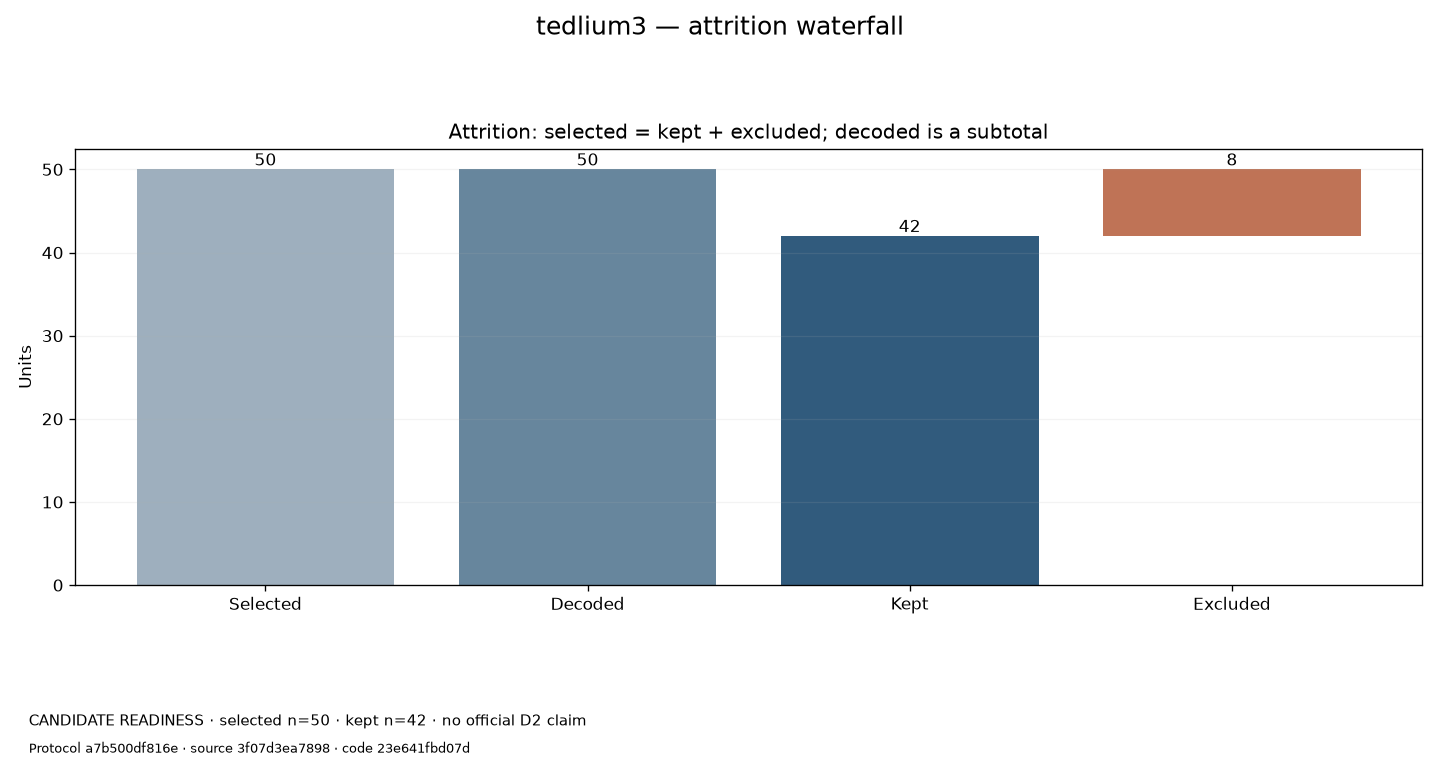

**tedlium3 — split_comparison**

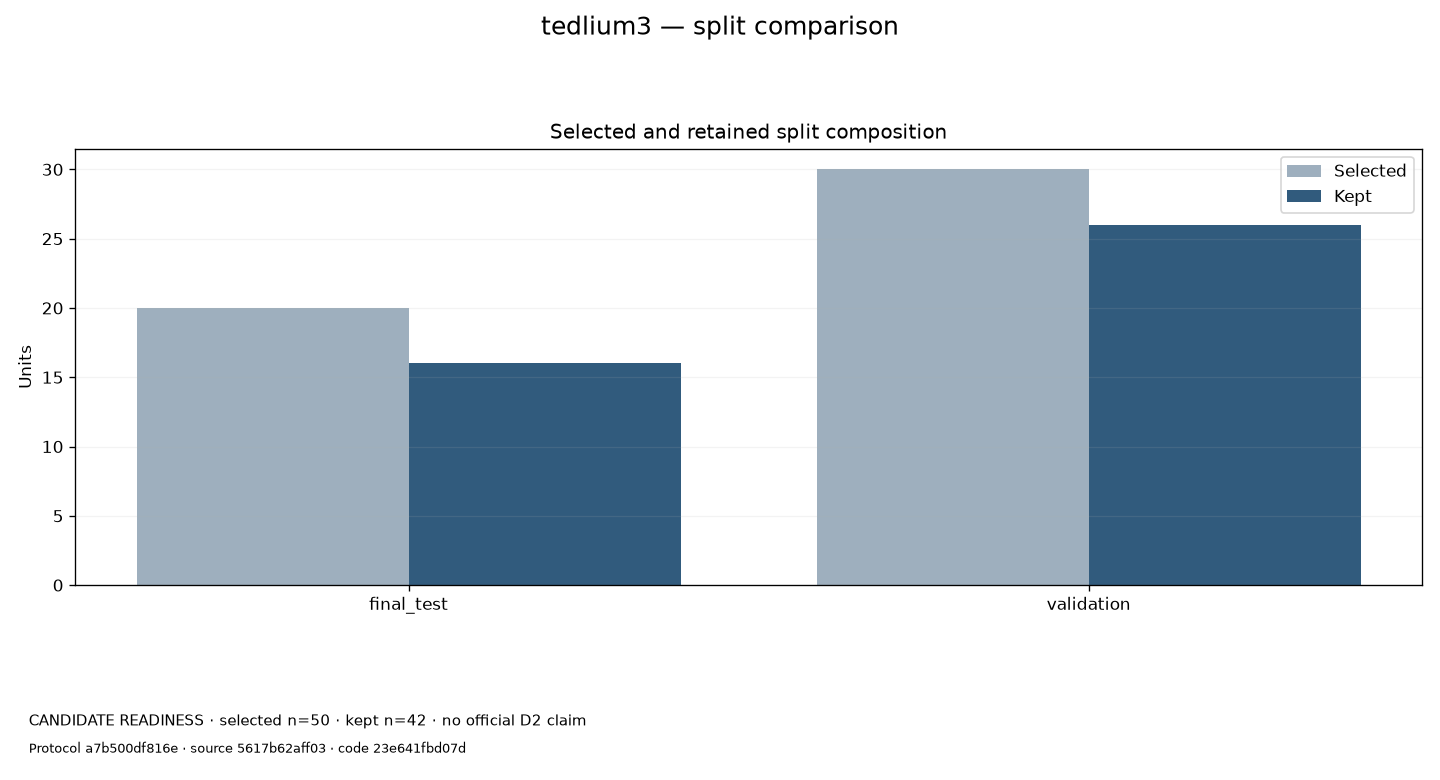

**tedlium3 — source_overlap**

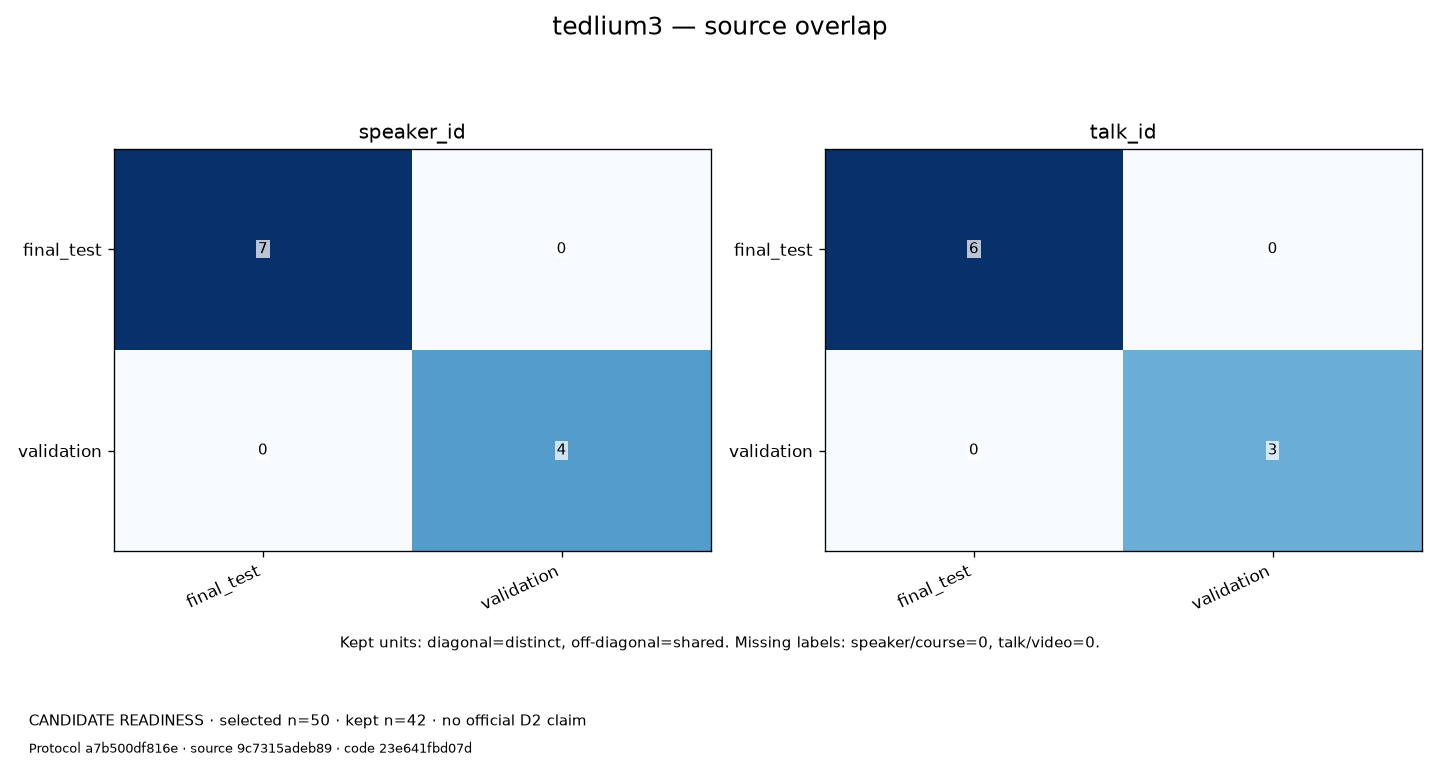

**tedlium3 — duplicate_matrix**

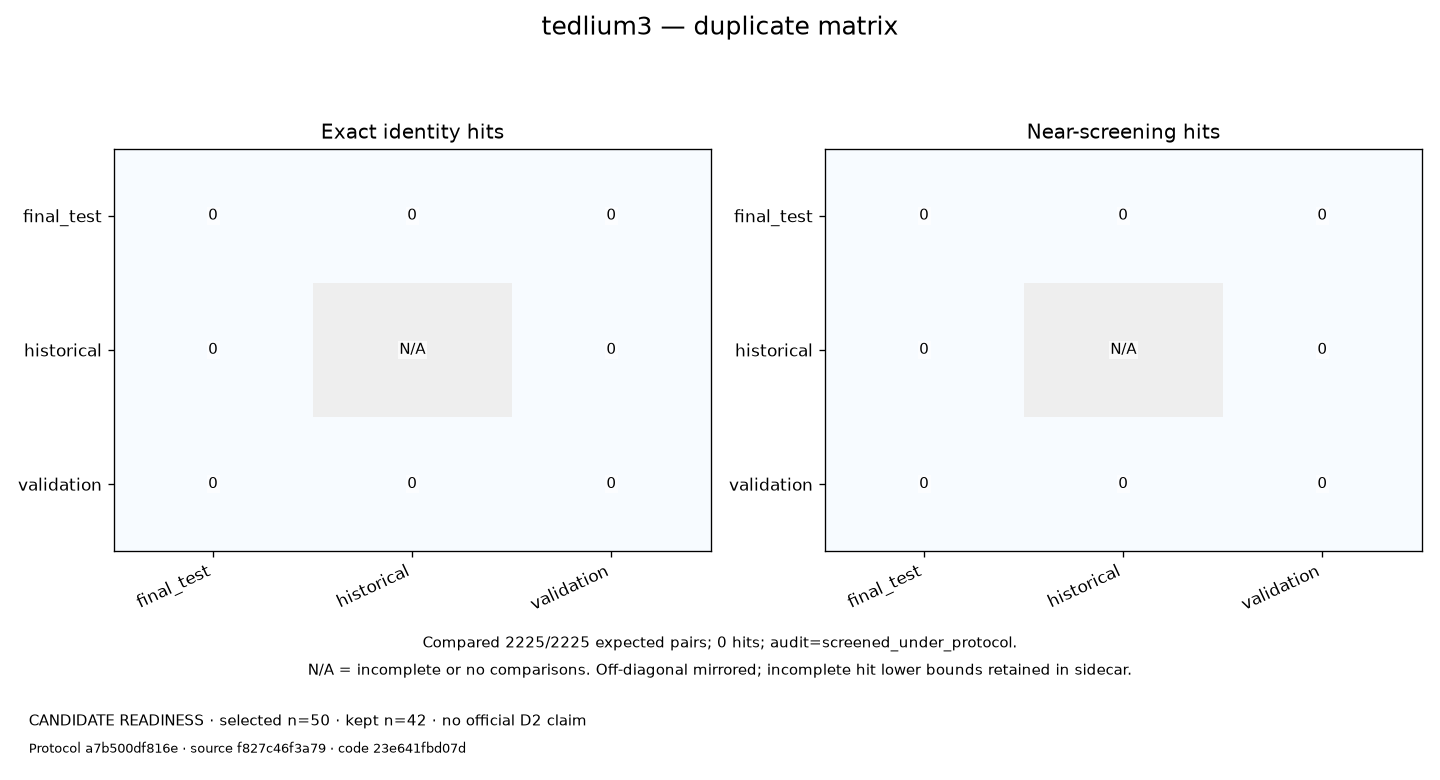

**iiit_cvid — scale_bytes**

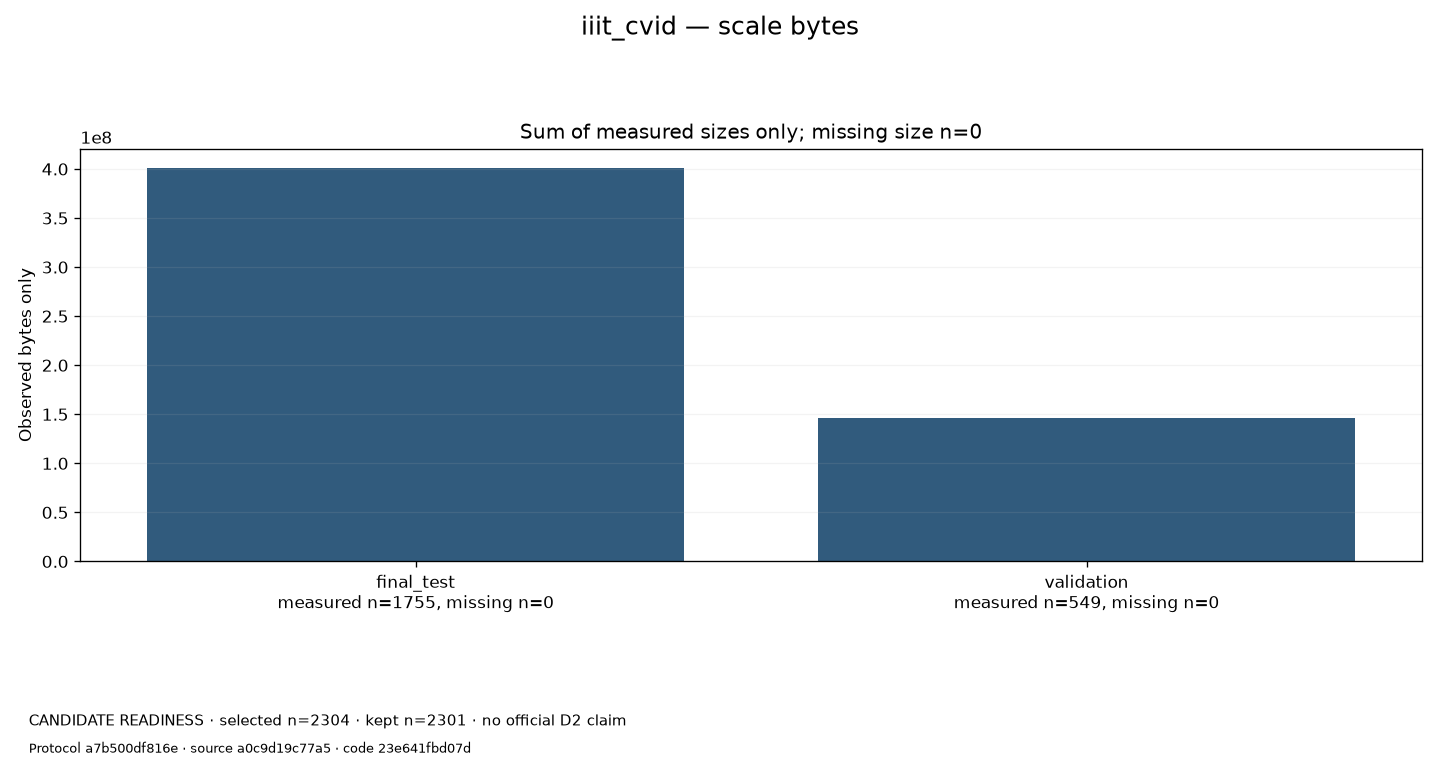

**iiit_cvid — duration_distribution**

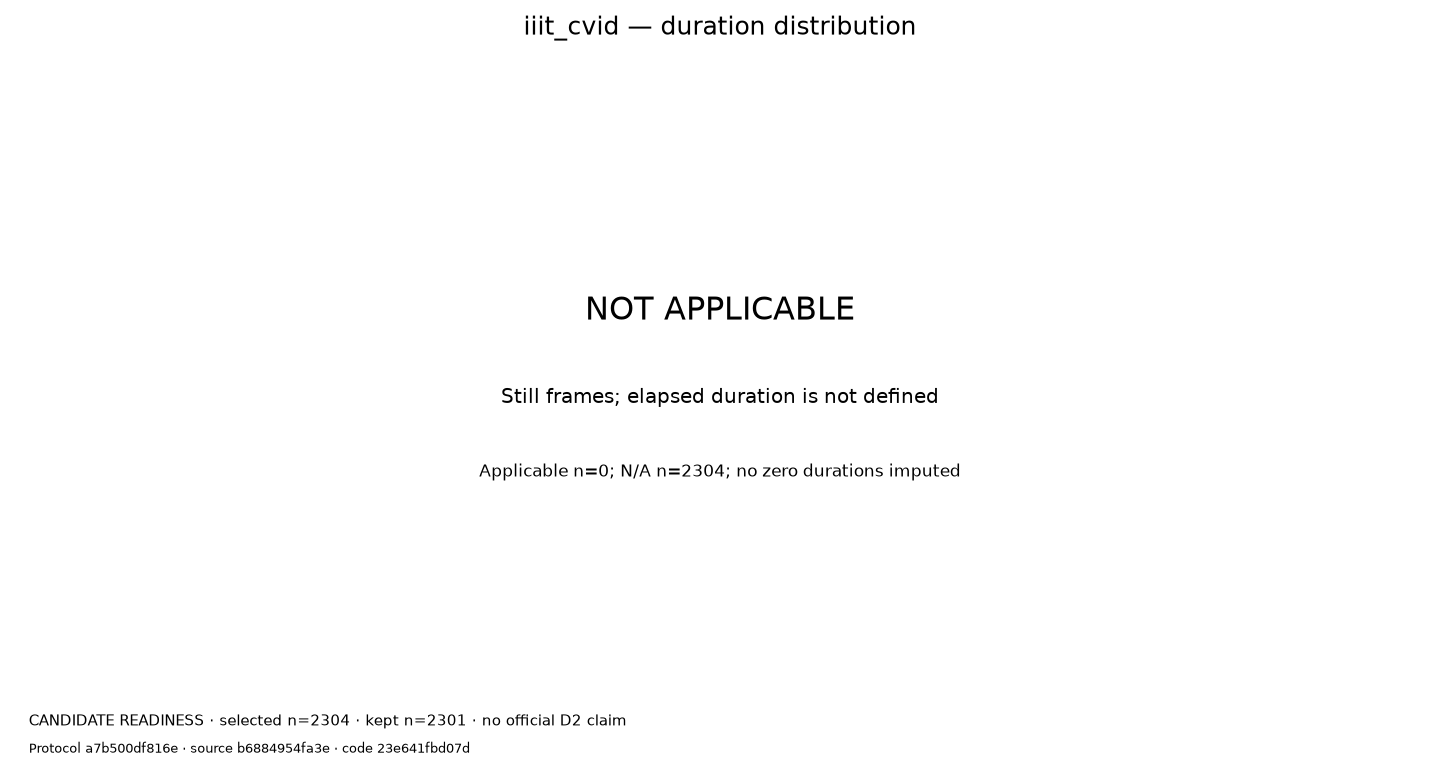

**iiit_cvid — file_size_distribution**

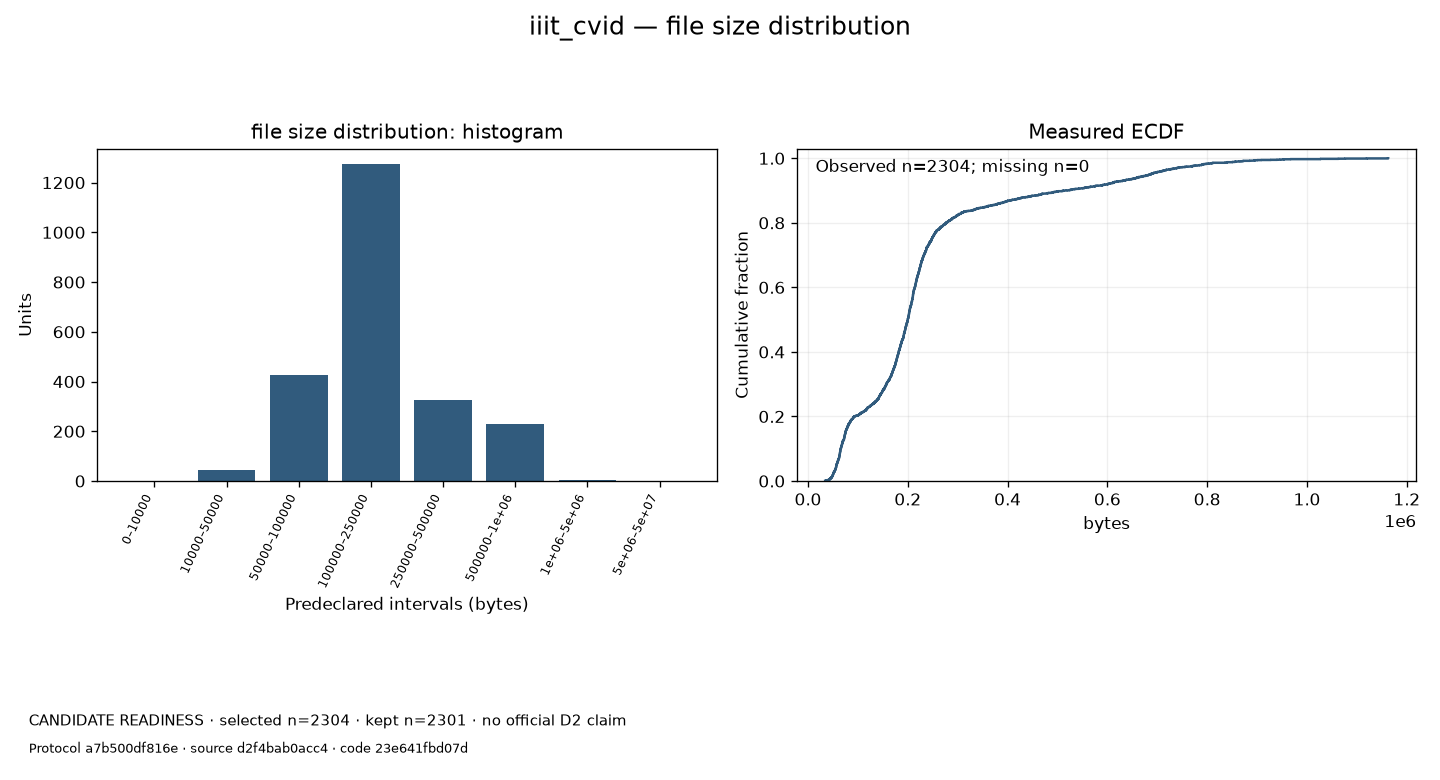

**iiit_cvid — missingness_gt_coverage**

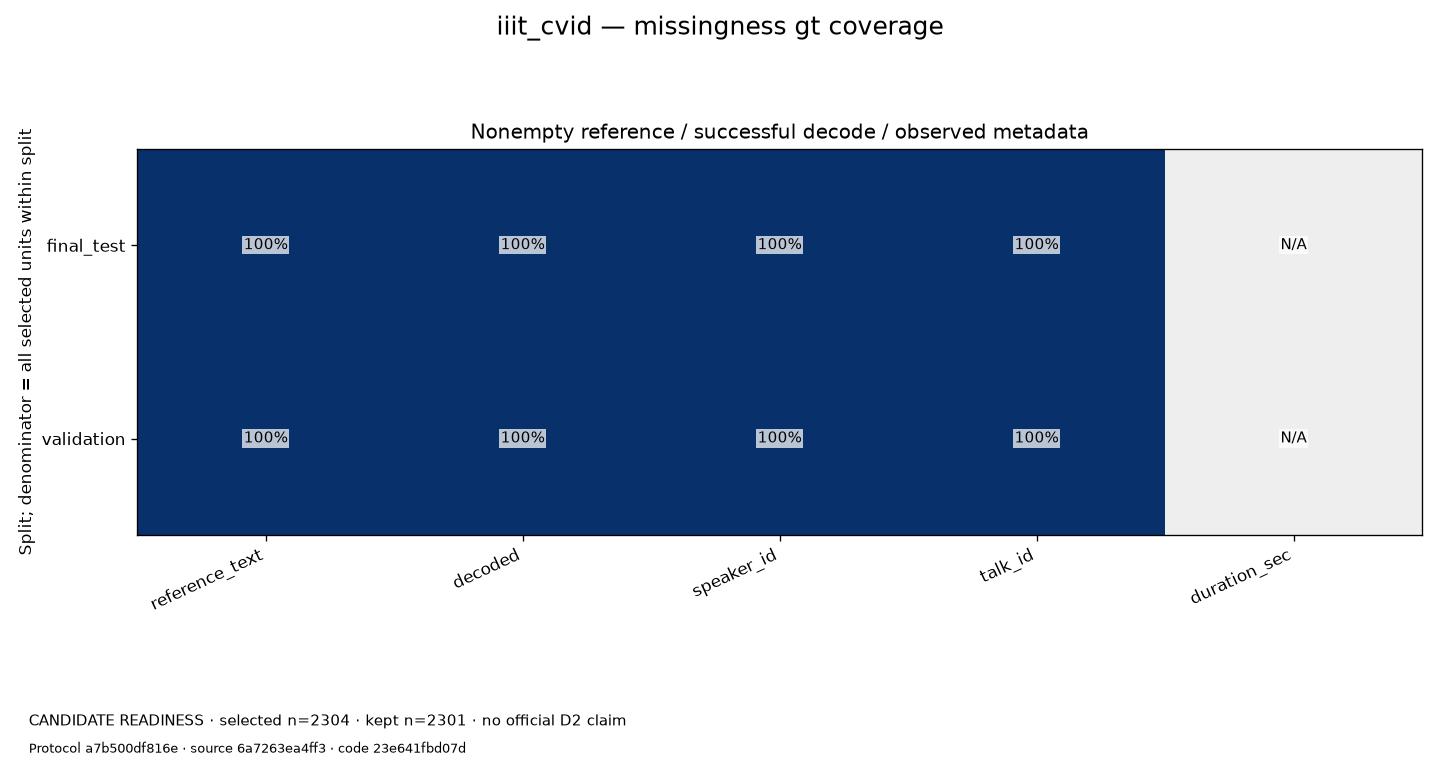

**iiit_cvid — attrition_waterfall**

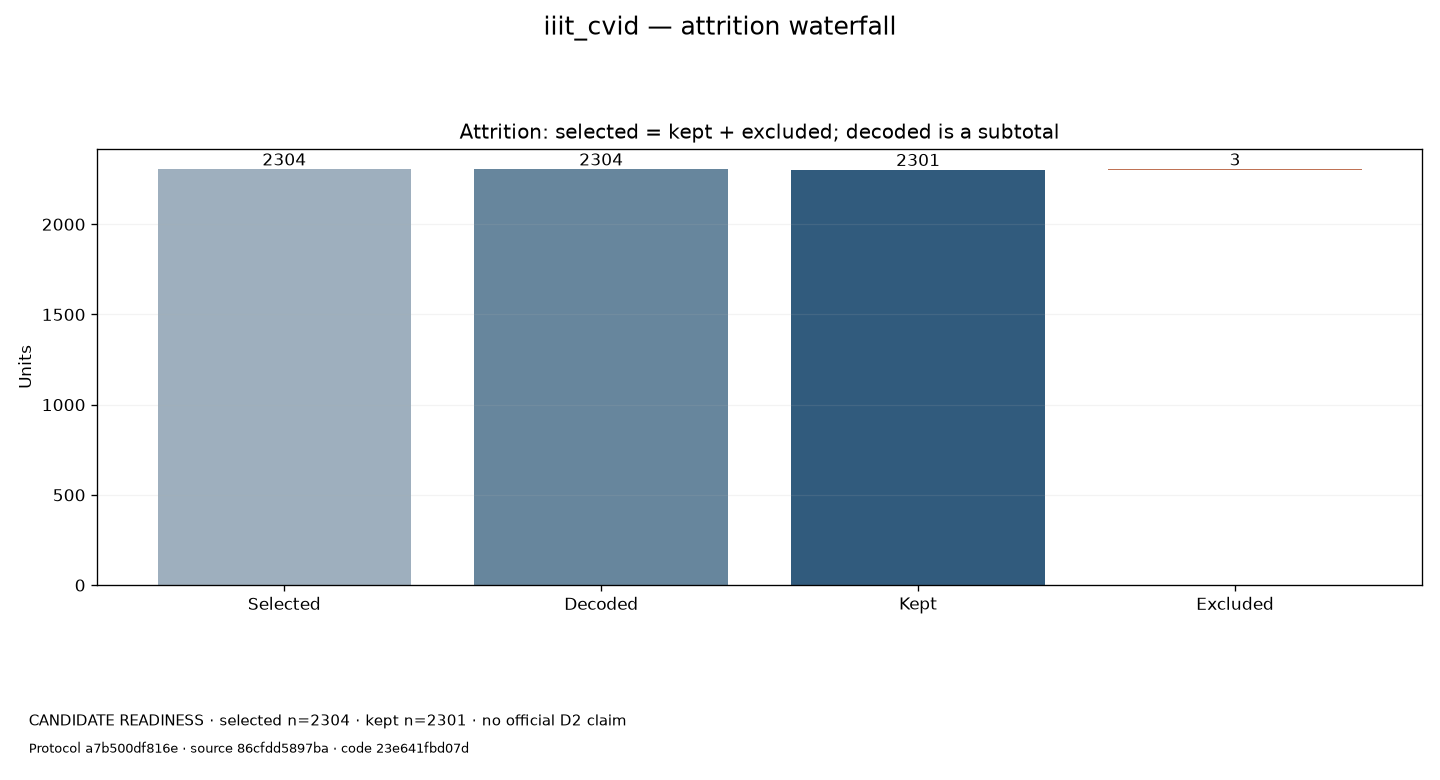

**iiit_cvid — split_comparison**

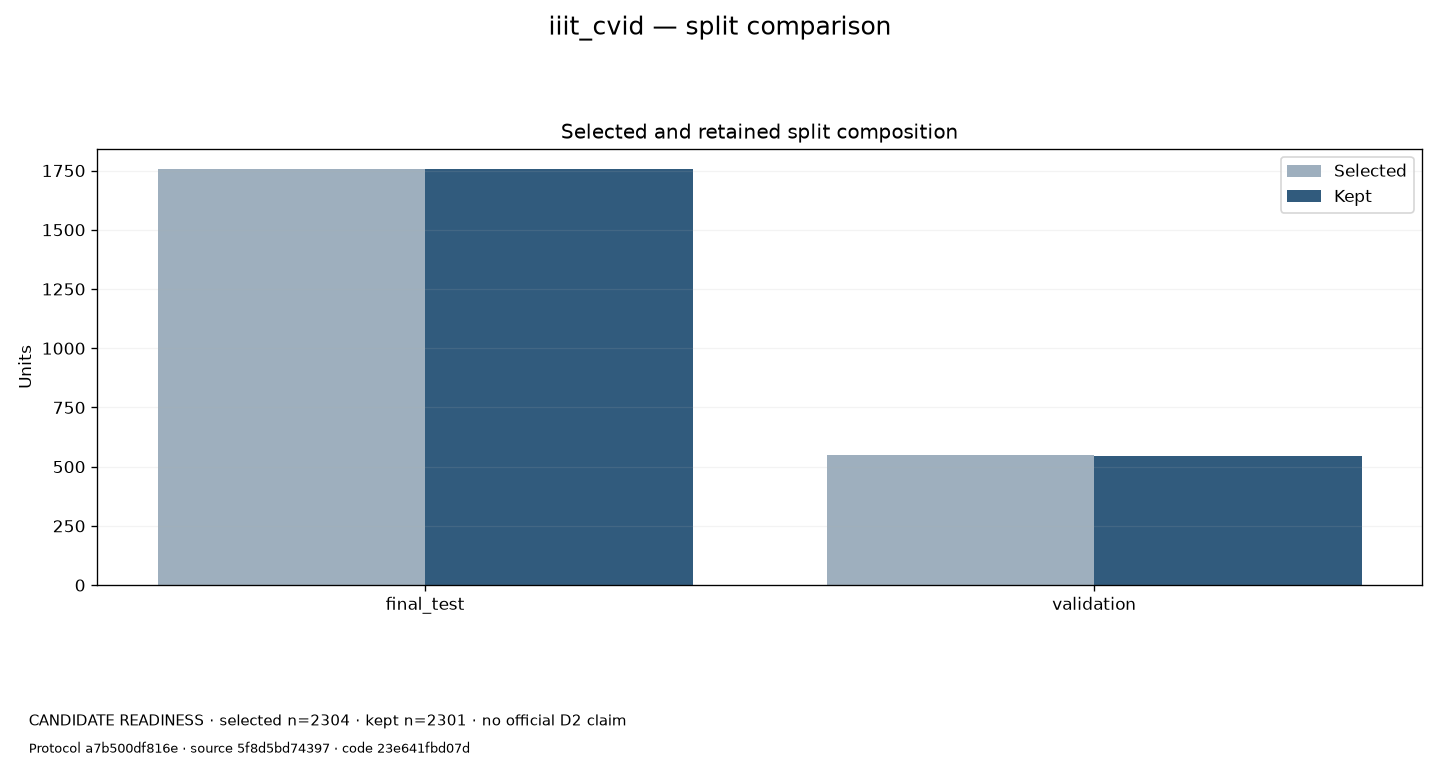

**iiit_cvid — source_overlap**

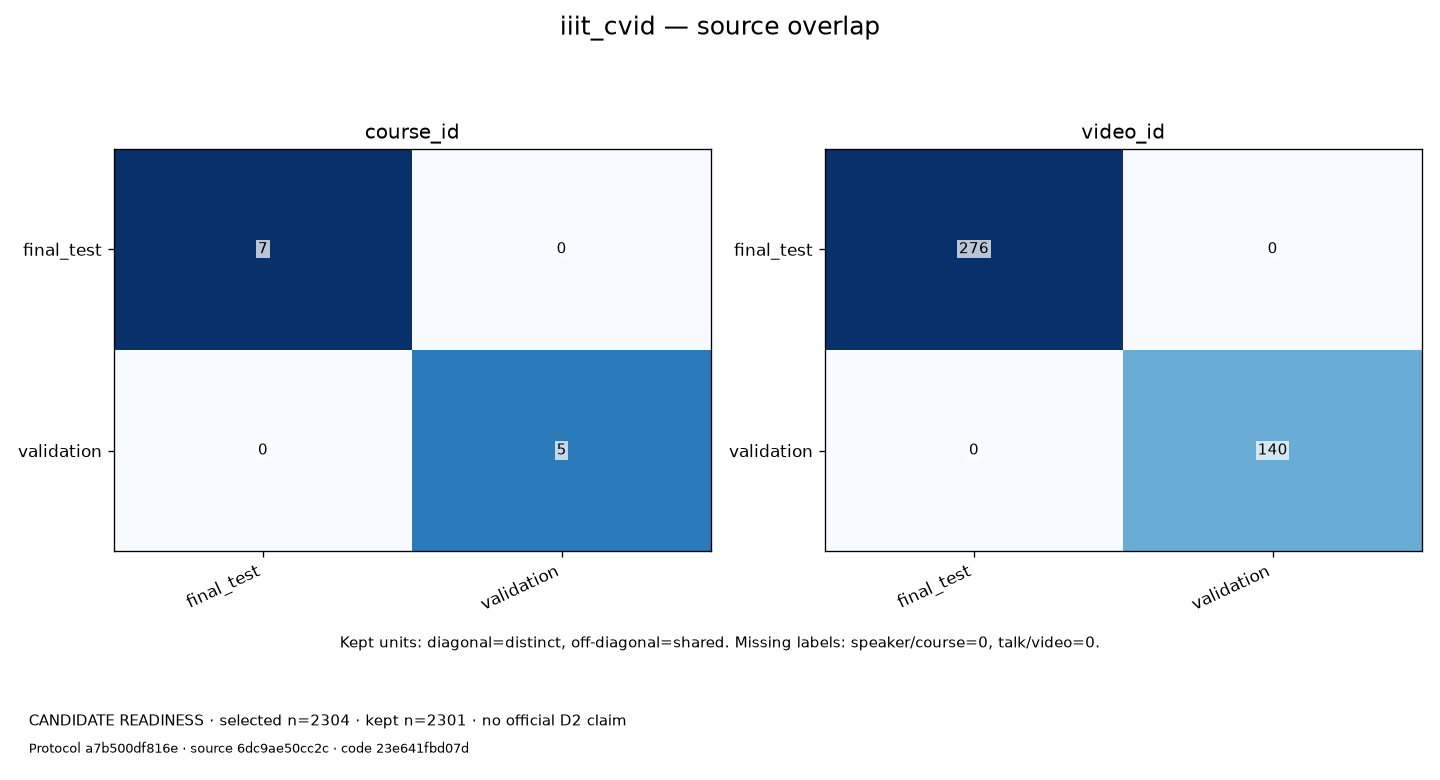

**iiit_cvid — duplicate_matrix**

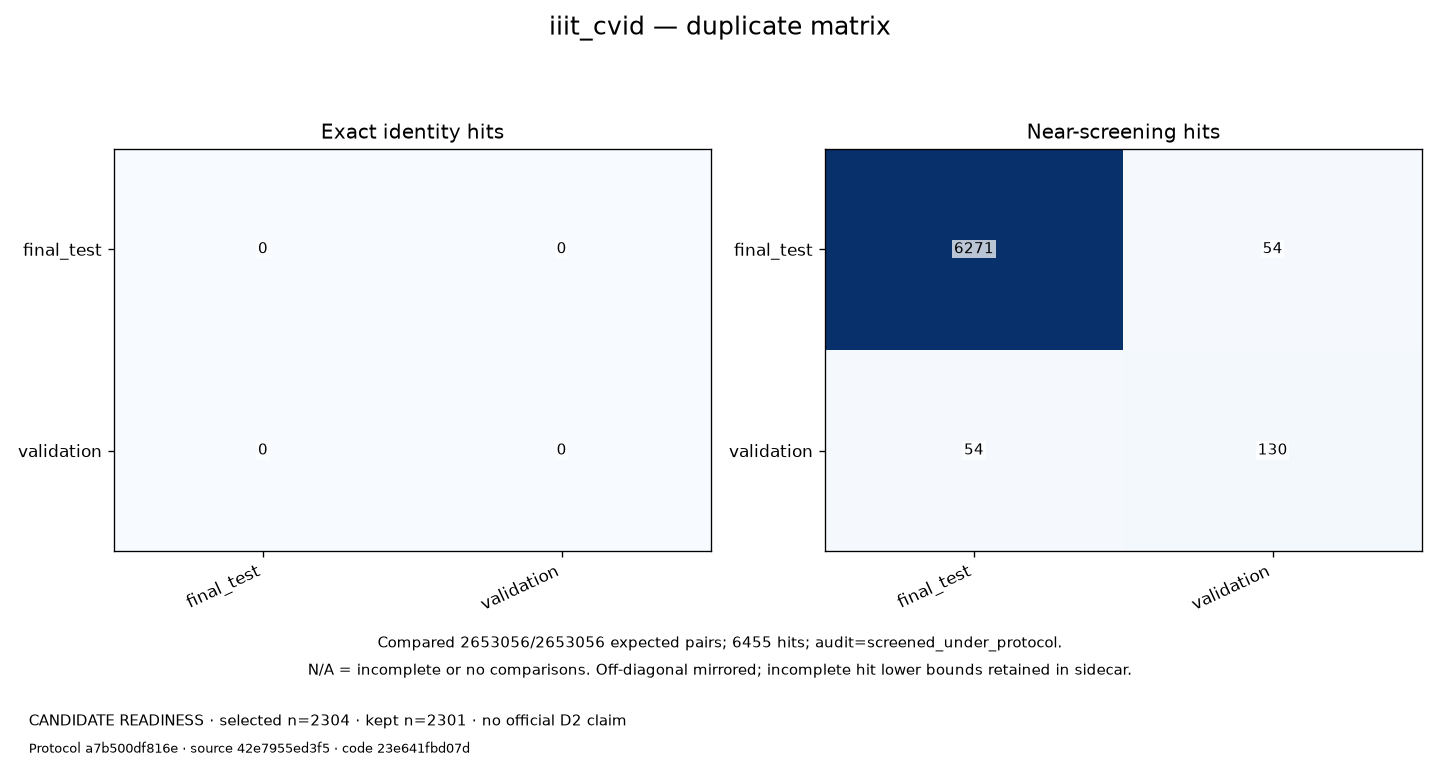

In [5]:
figure_count = 0
for dataset in summary:
    manifest = json.loads((BUNDLE / dataset / "figure-manifest.json").read_text(encoding="utf-8"))
    assert len(manifest) == 8
    for figure in manifest:
        path = Path(figure["path"])
        if not path.is_absolute(): path = BUNDLE / path
        path.resolve().relative_to(BUNDLE.resolve())
        assert sha256_file(path) == figure["sha256"]
        display(Markdown(f"**{dataset} — {figure['figure_id']}**"))
        display(Image(filename=str(path)))
        figure_count += 1
assert figure_count == 16


## Historical preservation and conclusion

In [6]:
baseline = json.loads((ROOT.parent / "plans/260926-1651-dataset-readiness/historical-before.json").read_text(encoding="utf-8-sig"))
changed = [r["path"] for r in baseline if sha256_file(Path(r["path"])).lower() != r["sha256"].lower()]
print("Historical files:", len(baseline), "changed:", changed)
assert not changed
assert all(c["accepted"] for c in commands)
display(pd.DataFrame([{k:c[k] for k in ("command", "exit_code", "accepted")} for c in commands]))
print("Prepared cohorts are screened under the saved protocol. No model inference, candidate ranking, official D2 promotion or full-DAG completion is claimed.")
print("Bundle:", BUNDLE)


Historical files: 602 changed: []


,command,exit_code,accepted
0,[C:\Users\hung\AppData\Local\Programs\Python\P...,0,True
1,[C:\Users\hung\AppData\Local\Programs\Python\P...,0,True
2,"[git, diff, --check]",0,True
3,[C:\Users\hung\AppData\Local\Programs\Python\P...,0,True


Prepared cohorts are screened under the saved protocol. No model inference, candidate ranking, official D2 promotion or full-DAG completion is claimed.
Bundle: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\dataset_readiness_260926\20260926T101747121197Z\bundle
